# Workers, threads and processes, with `dask_setup`

The question that comes up at every Dask tutorial: **what is the difference between a worker, a thread
and a process, and why does `workload_type` change them?**

This notebook answers it by experiment. Every cell runs on a laptop or a Gadi compute node; the numbers
you get will differ, but the *pattern* won't.

| # | Section | You will see |
|---|---------|--------------|
| 1 | Vocabulary | The three words, and how Dask maps them onto each other |
| 2 | What `dask_setup` builds | The topology each `workload_type` produces on this machine and on a 48-core Gadi job |
| 3 | Look inside a cluster | Which process and thread each task actually ran on |
| 4 | The GIL experiment | Pure Python vs GIL-releasing C vs waiting, on threads and on processes |
| 5 | The cost of a process | Moving a large array out of a separate process |
| 6 | Memory is per worker | How the same node's memory is split by each topology |
| 7 | Threads on threads | BLAS thread pools inside Dask threads |
| 8 | Cheat sheet | What to pick, and how to check what you got |

**Requirements:** `dask_setup`, `numpy`, `pandas`, `matplotlib`.

## 1. Vocabulary

| Term | Owned by | What it is | Shares memory with... |
|---|---|---|---|
| **Process** | Operating system | A running Python interpreter with its own memory and its own **GIL** | nothing (data must be pickled and copied) |
| **Thread** | Operating system | A line of execution inside a process | every other thread in the same process |
| **Worker** | Dask | A server that takes tasks from the scheduler, runs them on `threads_per_worker` threads, stores results, and enforces a memory limit | its own threads |

How workers sit on processes is a cluster setting:

```
processes=True   (workload_type="cpu" / "mixed")        processes=False   (workload_type="io")

 notebook process        worker processes                 notebook process
┌──────────────┐   ┌──────────┐ ┌──────────┐            ┌──────────────────────────────┐
│ client       │   │ worker 0 │ │ worker 1 │  ...       │ client                       │
│ scheduler    │──▶│  thread  │ │  thread  │            │ scheduler                    │
└──────────────┘   │  own GIL │ │  own GIL │            │ worker 0: thread thread ...  │
                   └──────────┘ └──────────┘            │           one shared GIL     │
                                                        └──────────────────────────────┘
```

**Total parallel slots = `n_workers × threads_per_worker`.** The rest of this notebook is about how to
spend those slots.

In [1]:
import hashlib
import os
import threading
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import dask
import distributed
import dask_setup
from dask_setup import DaskClientContext
from dask_setup.resources import detect_resources
from dask_setup.topology import decide_topology
from dask_setup.cluster import calculate_memory_spec

print(f"dask_setup  {dask_setup.__version__}")
print(f"dask        {dask.__version__}")
print(f"distributed {distributed.__version__}")

res = detect_resources()
CORES = res.total_cores
print(f"\nDetected via : {res.detection_method}")
print(f"Cores        : {CORES}")
print(f"Memory       : {res.total_mem_bytes / 2**30:.1f} GiB")

INFO     [resources] Resources detected via PBS (total_cores=104 | total_mem_gib=496.0)


dask_setup  2.3.0
dask        2026.1.2
distributed 2026.1.2

Detected via : PBS
Cores        : 104
Memory       : 496.0 GiB


On a Gadi compute node, `detection_method` should say `pbs`: `dask_setup` reads `ncpus` and `mem`
from your job, not the whole node. On a laptop it falls back to `psutil`.

## 2. What `dask_setup` builds

`workload_type` is really a choice of **topology**. `decide_topology()` is the pure function
`setup_dask_client()` uses, so we can ask it directly without starting anything:

In [2]:
def topology_table(total_cores):
    rows = []
    for wt in ["cpu", "mixed", "io"]:
        t = decide_topology(wt, total_cores=total_cores)
        rows.append(
            {
                "workload_type": wt,
                "workers": t.n_workers,
                "threads/worker": t.threads_per_worker,
                "processes": t.processes,
                "total slots": t.n_workers * t.threads_per_worker,
            }
        )
    return pd.DataFrame(rows).set_index("workload_type")


print(f"This machine ({CORES} cores):")
display(topology_table(CORES))

print("A Gadi job with ncpus=48:")
display(topology_table(48))

This machine (104 cores):


,workers,threads/worker,processes,total slots
workload_type,,,,
cpu,104,1,True,104
mixed,52,2,True,104
io,1,16,False,16


A Gadi job with ncpus=48:


,workers,threads/worker,processes,total slots
workload_type,,,,
cpu,48,1,True,48
mixed,24,2,True,48
io,1,16,False,16


Things to notice:

- **`cpu`**: one worker per core, each in its own process with one thread. Every task gets its own GIL.
- **`mixed`**: half as many workers, two threads each.
- **`io`**: a *single* worker, living in your notebook's process, with 4–16 threads. Threads that are
  mostly waiting don't need a core each, and there is nothing to copy between processes.

## 3. Look inside a cluster

Let's start real clusters and ask every task *where am I running?* `max_workers=4` keeps the demo
small. `dashboard=False` keeps the output quiet; turn it on and watch the *Workers* tab if you like.

In [3]:
def whoami(i):
    from distributed import get_worker

    return {
        "task": i,
        "worker": get_worker().name,
        "pid": os.getpid(),
        "thread": threading.current_thread().name,
    }


def inspect_cluster(workload_type, n_tasks=12, **kwargs):
    with DaskClientContext(
        mode="interactive", workload_type=workload_type, dashboard=False, **kwargs
    ) as (client, cluster, tmp):
        nthreads = client.nthreads()  # {worker address: threads}
        pids = client.run(os.getpid)  # {worker address: pid}
        info = client.scheduler_info()["workers"]

        print(f"=== workload_type={workload_type!r} ===")
        print(f"notebook (client) pid: {os.getpid()}")
        for addr in nthreads:
            print(
                f"  worker {addr:<28} pid={pids[addr]:<8} threads={nthreads[addr]:<3} "
                f"memory_limit={info[addr]['memory_limit'] / 2**30:.1f} GiB"
            )

        # Make each task last a moment so they spread over all slots
        futures = client.map(lambda i: (time.sleep(0.2), whoami(i))[1], range(n_tasks), pure=False)
        df = pd.DataFrame(client.gather(futures)).set_index("task")
    return df


cpu_df = inspect_cluster("cpu", max_workers=4)
cpu_df

INFO     [client] Starting Dask client setup (workload_type=cpu | environment=jupyter)
INFO     [resources] Resources detected via PBS (total_cores=104 | total_mem_gib=496.0)
INFO     [client] Temp/spill dir: /jobfs/181538335.gadi-pbs/dask-489321
INFO     [client] Workers: 4 | threads/worker: 1 | processes: True
INFO     [client] Mem: total ~496.0 GiB | usable ~446.0 GiB | per-worker ~111.5 GiB
INFO     [client] Compression: spill=auto | comm=False
INFO     [client] Dask client ready


[setup_dask_client] Configuration summary
temp/spill dir: /jobfs/181538335.gadi-pbs/dask-489321
Workers: 4 | threads/worker: 1 | processes: True
Memory: total ~496.0 GiB | usable ~446.0 GiB | per-worker ~111.5 GiB
Compression: spill=auto | comm=False
=== workload_type='cpu' ===
notebook (client) pid: 489321
  worker tcp://127.0.0.1:36695        pid=489954   threads=1   memory_limit=111.5 GiB
  worker tcp://127.0.0.1:42355        pid=489956   threads=1   memory_limit=111.5 GiB
  worker tcp://127.0.0.1:43517        pid=489952   threads=1   memory_limit=111.5 GiB
  worker tcp://127.0.0.1:44797        pid=489950   threads=1   memory_limit=111.5 GiB


INFO     [client] Cluster run summary: wall=1.8s | workers=4 | mem=0.10 GiB/max | tasks=12


,worker,pid,thread
task,,,
0,0,489950,Dask-Default-Threads-489950-0
1,2,489952,2-Dask-Default-Threads-489952-0
2,3,489956,3-Dask-Default-Threads-489956-0
3,1,489954,1-Dask-Default-Threads-489954-0
4,0,489950,Dask-Default-Threads-489950-0
5,2,489952,2-Dask-Default-Threads-489952-0
6,3,489956,3-Dask-Default-Threads-489956-0
7,1,489954,1-Dask-Default-Threads-489954-0
8,0,489950,Dask-Default-Threads-489950-0


In [4]:
print("Distinct processes used :", cpu_df.pid.nunique())
print("Distinct threads used   :", cpu_df.groupby(["pid", "thread"]).ngroups)
print("Tasks ran in the notebook's own process?", (cpu_df.pid == os.getpid()).any())

Distinct processes used : 4
Distinct threads used   : 4
Tasks ran in the notebook's own process? False


In [5]:
io_df = inspect_cluster("io")
io_df

INFO     [client] Starting Dask client setup (workload_type=io | environment=jupyter)
INFO     [resources] Resources detected via PBS (total_cores=104 | total_mem_gib=496.0)
INFO     [client] Temp/spill dir: /jobfs/181538335.gadi-pbs/dask-489321
INFO     [client] Workers: 1 | threads/worker: 16 | processes: False
INFO     [client] Mem: total ~496.0 GiB | usable ~446.0 GiB | per-worker ~446.0 GiB
INFO     [client] Compression: spill=auto | comm=False
INFO     [client] Dask client ready


[setup_dask_client] Configuration summary
temp/spill dir: /jobfs/181538335.gadi-pbs/dask-489321
Workers: 1 | threads/worker: 16 | processes: False
Memory: total ~496.0 GiB | usable ~446.0 GiB | per-worker ~446.0 GiB
Compression: spill=auto | comm=False
=== workload_type='io' ===
notebook (client) pid: 489321
  worker inproc://10.6.82.47/489321/4 pid=489321   threads=16  memory_limit=446.0 GiB


INFO     [client] Cluster run summary: wall=0.3s | workers=1 | mem=0.27 GiB/max | tasks=12


,worker,pid,thread
task,,,
0,0,489321,Dask-Default-Threads-489321-0
1,0,489321,Dask-Default-Threads-489321-1
2,0,489321,Dask-Default-Threads-489321-2
3,0,489321,Dask-Default-Threads-489321-3
4,0,489321,Dask-Default-Threads-489321-4
5,0,489321,Dask-Default-Threads-489321-5
6,0,489321,Dask-Default-Threads-489321-6
7,0,489321,Dask-Default-Threads-489321-7
8,0,489321,Dask-Default-Threads-489321-8


In [6]:
print("Distinct processes used :", io_df.pid.nunique())
print("Distinct threads used   :", io_df.groupby(["pid", "thread"]).ngroups)
print("Tasks ran in the notebook's own process?", (io_df.pid == os.getpid()).all())

Distinct processes used : 1
Distinct threads used   : 12
Tasks ran in the notebook's own process? True


**What you should see**

- `cpu`: four different PIDs, none of them the notebook's. Each worker is its own process, so each
  has its own memory and its own GIL.
- `io`: one PID, and it **is** the notebook's. The single worker runs its tasks on a pool of threads
  inside your kernel. Its memory limit is the whole usable budget.

So far, so abstract. The next experiment shows why it matters.

## 4. The GIL experiment

We time three kinds of task on both topologies:

| Task | What it does | Holds the GIL? | Real-world stand-in |
|---|---|---|---|
| `python_loop` | Sums squares in a plain `for` loop | **yes**, the whole time | pure-Python code, pandas `apply`, NetCDF/HDF5 reads |
| `c_hash` | SHA-256 over a 32 MiB buffer | **no**, `hashlib` releases it | NumPy kernels, Zarr codecs |
| `wait_io` | `time.sleep` | **no**, sleeping releases it | waiting on disk, network, object storage |

For a fair fight both clusters get the **same number of slots**: `io` picks its thread count, and we
give `cpu` the same number of worker processes with `max_workers=`.

First, calibrate each task to take about half a second on this machine:

In [7]:
TARGET_S = 0.5
BUF = 32 * 2**20  # 32 MiB


def python_loop(i, n):
    total = 0
    for k in range(n):
        total += k * k
    return total


def c_hash(i, repeats):
    buf = b"\0" * BUF  # built inside the task so nothing big is shipped to the worker
    h = hashlib.sha256()
    for _ in range(repeats):
        h.update(buf)  # hashlib releases the GIL for large buffers
    return h.hexdigest()[:8]


def wait_io(i, seconds):
    time.sleep(seconds)
    return i


def calibrate(fn, probe_arg, scale_int=True):
    t0 = time.perf_counter()
    fn(0, probe_arg)
    dt = time.perf_counter() - t0
    arg = probe_arg * TARGET_S / dt
    return max(1, round(arg)) if scale_int else arg


TASKS = {
    "python_loop": (python_loop, calibrate(python_loop, 2_000_000)),
    "c_hash": (c_hash, calibrate(c_hash, 4)),
    "wait_io": (wait_io, TARGET_S),
}

# Measure the serial (single-task) time of each, in the notebook, for the speed-up baseline
SERIAL = {}
for name, (fn, arg) in TASKS.items():
    t0 = time.perf_counter()
    fn(0, arg)
    SERIAL[name] = time.perf_counter() - t0
    print(f"{name:<12} arg={arg!s:<12} one task = {SERIAL[name]:.2f} s")

python_loop  arg=12462616     one task = 0.38 s
c_hash       arg=22           one task = 0.42 s
wait_io      arg=0.5          one task = 0.50 s


In [8]:
SLOTS = decide_topology("io", total_cores=CORES).threads_per_worker
N_TASKS = 2 * SLOTS
print(f"Both clusters get {SLOTS} slots; each run submits {N_TASKS} tasks.")
if SLOTS > CORES:
    print(f"(Only {CORES} cores here, so `cpu` will be capped at {CORES} workers.)")


def time_batch(client, fn, arg, n_tasks):
    t0 = time.perf_counter()
    futures = client.map(fn, range(n_tasks), [arg] * n_tasks, pure=False)
    client.gather(futures)
    return time.perf_counter() - t0


def run_experiment(workload_type, **kwargs):
    rows = []
    with DaskClientContext(
        mode="interactive", workload_type=workload_type, dashboard=False, **kwargs
    ) as (client, cluster, tmp):
        slots = sum(client.nthreads().values())
        time_batch(client, wait_io, 0.01, slots)  # warm-up: workers started, functions imported
        for name, (fn, arg) in TASKS.items():
            wall = time_batch(client, fn, arg, N_TASKS)
            speedup = SERIAL[name] * N_TASKS / wall
            rows.append(
                {
                    "workload_type": workload_type,
                    "task": name,
                    "slots": slots,
                    "wall (s)": round(wall, 2),
                    "speed-up": round(speedup, 1),
                    "efficiency": f"{speedup / slots:.0%}",
                }
            )
            print(f"  {workload_type:<4} {name:<12} {wall:6.2f} s   speed-up x{speedup:.1f}")
    return rows


results = pd.DataFrame(
    run_experiment("cpu", max_workers=SLOTS) + run_experiment("io")
)
results.set_index(["task", "workload_type"]).sort_index()

INFO     [client] Starting Dask client setup (workload_type=cpu | environment=jupyter)
INFO     [resources] Resources detected via PBS (total_cores=104 | total_mem_gib=496.0)


Both clusters get 16 slots; each run submits 32 tasks.


INFO     [client] Temp/spill dir: /jobfs/181538335.gadi-pbs/dask-489321
INFO     [client] Workers: 16 | threads/worker: 1 | processes: True
INFO     [client] Mem: total ~496.0 GiB | usable ~446.0 GiB | per-worker ~27.9 GiB
INFO     [client] Compression: spill=auto | comm=False
INFO     [client] Dask client ready


[setup_dask_client] Configuration summary
temp/spill dir: /jobfs/181538335.gadi-pbs/dask-489321
Workers: 16 | threads/worker: 1 | processes: True
Memory: total ~496.0 GiB | usable ~446.0 GiB | per-worker ~27.9 GiB
Compression: spill=auto | comm=False
  cpu  python_loop    0.99 s   speed-up x12.2
  cpu  c_hash         1.00 s   speed-up x13.4


INFO     [client] Cluster run summary: wall=4.7s | workers=16 | mem=0.00 GiB/max | tasks=20


...

INFO     [client] Starting Dask client setup (workload_type=io | environment=jupyter)
INFO     [resources] Resources detected via PBS (total_cores=104 | total_mem_gib=496.0)
INFO     [client] Temp/spill dir: /jobfs/181538335.gadi-pbs/dask-489321
INFO     [client] Workers: 1 | threads/worker: 16 | processes: False
INFO     [client] Mem: total ~496.0 GiB | usable ~446.0 GiB | per-worker ~446.0 GiB
INFO     [client] Compression: spill=auto | comm=False
INFO     [client] Dask client ready


[setup_dask_client] Configuration summary
temp/spill dir: /jobfs/181538335.gadi-pbs/dask-489321
Workers: 1 | threads/worker: 16 | processes: False
Memory: total ~496.0 GiB | usable ~446.0 GiB | per-worker ~446.0 GiB
Compression: spill=auto | comm=False
  io   python_loop   55.51 s   speed-up x0.2
  io   c_hash         1.55 s   speed-up x8.7


INFO     [client] Cluster run summary: wall=58.2s | workers=1 | mem=0.00 GiB/max | tasks=19


  io   wait_io        1.07 s   speed-up x15.0


slots  wall (s)  speed-up efficiency
task        workload_type                                      
c_hash      cpu               16      1.00      13.4        84%
            io                16      1.55       8.7        54%
python_loop cpu               16      0.99      12.2        76%
            io                16     55.51       0.2         1%
wait_io     cpu               16      1.07      15.0        94%
            io                16      1.07      15.0        94%

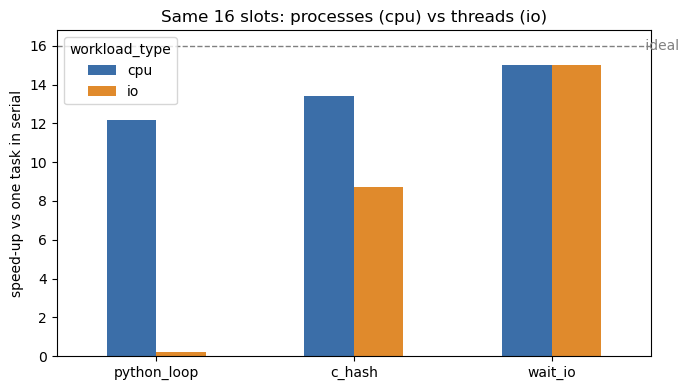

In [9]:
pivot = results.pivot(index="task", columns="workload_type", values="speed-up").loc[
    ["python_loop", "c_hash", "wait_io"]
]
ax = pivot.plot.bar(rot=0, figsize=(7, 4), color={"cpu": "#3b6ea8", "io": "#e08a2c"})
ax.axhline(results.slots.max(), ls="--", color="grey", lw=1)
ax.text(2.45, results.slots.max(), " ideal", va="center", color="grey")
ax.set_ylabel("speed-up vs one task in serial")
ax.set_xlabel("")
ax.set_title(f"Same {SLOTS} slots: processes (cpu) vs threads (io)")
plt.tight_layout()

**What you should see**

- **`python_loop`**: `cpu` gets close to the ideal line. `io` stays near **×1**: its threads queue
  for the one GIL, so adding threads adds nothing. This is the whole reason `workload_type="cpu"`
  exists, and why NetCDF/HDF5 reads (which hold a process-wide lock) belong on it too.
- **`c_hash`**: both topologies speed up, because `hashlib` releases the GIL while it works. (If this
  machine has fewer cores than slots, both flatten at the core count: real computation still needs
  a core.)
- **`wait_io`**: both reach the ideal. Sleeping threads use no CPU at all, which is why `io` can
  afford more threads than cores.

> **Try it:** change `TASKS["wait_io"]` to use 64 tasks and run `io` with `max_workers` left alone.
> Threads that wait are almost free; the same number of *processes* would cost 64 interpreters.

## 5. The cost of a process

Threads aren't just "processes that don't work"; they win whenever data has to move. A result that
lives in another process must be **pickled, sent over a socket and rebuilt**. A result in a threaded
worker is already in your memory.

Let's bring a 400 MB array back to the notebook from each topology:

In [10]:
ARRAY_MB = 400


def make_array(i, mb):
    return np.ones(mb * 2**20 // 8)  # float64


def time_transfer(workload_type, **kwargs):
    with DaskClientContext(
        mode="interactive", workload_type=workload_type, dashboard=False, **kwargs
    ) as (client, cluster, tmp):
        fut = client.submit(make_array, 0, ARRAY_MB, pure=False)
        distributed.wait(fut)  # array now exists on a worker
        t0 = time.perf_counter()
        arr = fut.result()  # move it to the notebook
        dt = time.perf_counter() - t0
    print(f"{workload_type:<4} fetched {arr.nbytes / 2**20:.0f} MiB in {dt * 1000:7.1f} ms")
    return dt


t_cpu = time_transfer("cpu", max_workers=2)
t_io = time_transfer("io")
print(f"\nCrossing a process boundary was ~{t_cpu / max(t_io, 1e-6):.0f}x slower here.")

INFO     [client] Starting Dask client setup (workload_type=cpu | environment=jupyter)
INFO     [resources] Resources detected via PBS (total_cores=104 | total_mem_gib=496.0)
INFO     [client] Temp/spill dir: /jobfs/181538335.gadi-pbs/dask-489321
INFO     [client] Workers: 2 | threads/worker: 1 | processes: True
INFO     [client] Mem: total ~496.0 GiB | usable ~446.0 GiB | per-worker ~223.0 GiB
INFO     [client] Compression: spill=auto | comm=False
INFO     [client] Dask client ready


[setup_dask_client] Configuration summary
temp/spill dir: /jobfs/181538335.gadi-pbs/dask-489321
Workers: 2 | threads/worker: 1 | processes: True
Memory: total ~496.0 GiB | usable ~446.0 GiB | per-worker ~223.0 GiB
Compression: spill=auto | comm=False


INFO     [client] Cluster run summary: wall=1.3s | workers=2 | mem=0.10 GiB/max | tasks=1
INFO     [client] Starting Dask client setup (workload_type=io | environment=jupyter)
INFO     [resources] Resources detected via PBS (total_cores=104 | total_mem_gib=496.0)
INFO     [client] Temp/spill dir: /jobfs/181538335.gadi-pbs/dask-489321
INFO     [client] Workers: 1 | threads/worker: 16 | processes: False
INFO     [client] Mem: total ~496.0 GiB | usable ~446.0 GiB | per-worker ~446.0 GiB
INFO     [client] Compression: spill=auto | comm=False
INFO     [client] Dask client ready
INFO     [client] Cluster run summary: wall=0.1s | workers=1 | mem=0.29 GiB/max | tasks=1


cpu  fetched 400 MiB in   276.0 ms
[setup_dask_client] Configuration summary
temp/spill dir: /jobfs/181538335.gadi-pbs/dask-489321
Workers: 1 | threads/worker: 16 | processes: False
Memory: total ~496.0 GiB | usable ~446.0 GiB | per-worker ~446.0 GiB
Compression: spill=auto | comm=False
io   fetched 400 MiB in     3.6 ms

Crossing a process boundary was ~76x slower here.


That cost is paid every time data crosses between workers too: in shuffles, rechunks, `.compute()`
on large results, and any reduction that gathers pieces from many workers. Fewer, fatter workers
(`mixed`, or `cpu` with `max_workers=`) pay it less often.

## 6. Memory is per worker

The memory limit belongs to the **worker**, and its threads share it. `dask_setup` first reserves
memory for the OS and filesystem (default: 20% of RAM, clamped to 4–50 GiB), then splits the rest
evenly between workers.

Here's the same 48-core, 190 GiB Gadi job under each topology:

In [11]:
NODE_CORES, NODE_MEM_GIB = 48, 190
reserve = min(50.0, max(4.0, 0.2 * NODE_MEM_GIB))  # dask_setup's default reserve

rows = []
for wt in ["cpu", "mixed", "io"]:
    t = decide_topology(wt, total_cores=NODE_CORES)
    m = calculate_memory_spec(NODE_MEM_GIB * 2**30, t.n_workers, reserve_mem_gb=reserve)
    per_worker = m.mem_per_worker_bytes / 2**30
    rows.append(
        {
            "workload_type": wt,
            "workers": t.n_workers,
            "threads/worker": t.threads_per_worker,
            "memory/worker (GiB)": round(per_worker, 1),
            "memory/thread (GiB)": round(per_worker / t.threads_per_worker, 1),
        }
    )

print(f"Reserved for OS: {reserve:.0f} GiB")
pd.DataFrame(rows).set_index("workload_type")

Reserved for OS: 38 GiB


,workers,threads/worker,memory/worker (GiB),memory/thread (GiB)
workload_type,,,,
cpu,48,1,3.2,3.2
mixed,24,2,6.3,3.2
io,1,16,152.0,9.5


A task usually needs its input chunk, its output chunk and a temporary or two **at the same time**.
So the practical rule is:

> **Keep chunks several times smaller than `memory/thread`.**

A 1 GiB chunk is comfortable for an `io` worker and marginal for a `cpu` worker with ~3 GiB, which
will start spilling to disk (at 75–85% of its limit) and may pause or be restarted (at 92–98%).
You don't have to do this arithmetic by hand: `setup_dask_client(..., ds=ds)` validates your chunks
against the cluster it just built, and `recommend_chunks()` suggests better ones.

## 7. Threads on threads

NumPy's linear algebra calls a BLAS library (OpenBLAS or MKL) that can start its *own* thread pool.
16 Dask threads each starting 48 BLAS threads is 768 threads on 48 cores.

Dask's nanny sets the usual BLAS variables to `1` inside the worker **processes** it launches. A
threaded (`io`) worker lives in your notebook process, so it inherits whatever your session has:

In [12]:
BLAS_VARS = ["OMP_NUM_THREADS", "MKL_NUM_THREADS", "OPENBLAS_NUM_THREADS"]


def blas_env():
    return {v: os.environ.get(v, "<unset>") for v in BLAS_VARS}


for wt, kw in [("cpu", {"max_workers": 1}), ("io", {})]:
    with DaskClientContext(mode="interactive", workload_type=wt, dashboard=False, **kw) as (
        client,
        cluster,
        tmp,
    ):
        env = next(iter(client.run(blas_env).values()))
    print(f"{wt:<4} worker: {env}")

INFO     [client] Starting Dask client setup (workload_type=cpu | environment=jupyter)
INFO     [resources] Resources detected via PBS (total_cores=104 | total_mem_gib=496.0)
INFO     [client] Temp/spill dir: /jobfs/181538335.gadi-pbs/dask-489321
INFO     [client] Workers: 1 | threads/worker: 1 | processes: True
INFO     [client] Mem: total ~496.0 GiB | usable ~446.0 GiB | per-worker ~446.0 GiB
INFO     [client] Compression: spill=auto | comm=False
INFO     [client] Dask client ready
INFO     [client] Cluster run summary: wall=0.7s | workers=1 | mem=0.10 GiB/max
INFO     [client] Starting Dask client setup (workload_type=io | environment=jupyter)
INFO     [resources] Resources detected via PBS (total_cores=104 | total_mem_gib=496.0)
INFO     [client] Temp/spill dir: /jobfs/181538335.gadi-pbs/dask-489321
INFO     [client] Workers: 1 | threads/worker: 16 | processes: False
INFO     [client] Mem: total ~496.0 GiB | usable ~446.0 GiB | per-worker ~446.0 GiB
INFO     [client] Compression: s

[setup_dask_client] Configuration summary
temp/spill dir: /jobfs/181538335.gadi-pbs/dask-489321
Workers: 1 | threads/worker: 1 | processes: True
Memory: total ~496.0 GiB | usable ~446.0 GiB | per-worker ~446.0 GiB
Compression: spill=auto | comm=False
cpu  worker: {'OMP_NUM_THREADS': '1', 'MKL_NUM_THREADS': '1', 'OPENBLAS_NUM_THREADS': '1'}
[setup_dask_client] Configuration summary
temp/spill dir: /jobfs/181538335.gadi-pbs/dask-489321
Workers: 1 | threads/worker: 16 | processes: False
Memory: total ~496.0 GiB | usable ~446.0 GiB | per-worker ~446.0 GiB
Compression: spill=auto | comm=False
io   worker: {'OMP_NUM_THREADS': '1', 'MKL_NUM_THREADS': '1', 'OPENBLAS_NUM_THREADS': '1'}


If you run BLAS-heavy code (matrix products, `np.linalg`, scikit-learn) on an `io` cluster, set these
to `1` **before Python starts**, e.g. in your PBS script:

```bash
export OMP_NUM_THREADS=1 MKL_NUM_THREADS=1 OPENBLAS_NUM_THREADS=1
```

## 8. Cheat sheet

| If the hot code... | Examples | Pick | Why |
|---|---|---|---|
| holds the GIL | pure Python, pandas `apply`, **NetCDF / HDF5 reads** | `"cpu"` | one GIL (and one HDF5 lock) per process |
| releases the GIL | **Zarr**, object storage, NumPy-heavy maths | `"io"` | threads run concurrently, no copies, one big memory pool |
| does a bit of both, or you're not sure | general analysis pipelines | `"mixed"` | 2 threads per process: a hedge |
| runs on GPUs | CuPy, RAPIDS | `"gpu"` | one worker per GPU |

**Checking what you got**

```python
client                      # repr shows workers, threads and memory
client.nthreads()           # {worker address: threads}
client.run(os.getpid)       # {worker address: pid}; same pid as the notebook means threads only
client.scheduler_info()["workers"][addr]["memory_limit"]
```

or open the dashboard's **Workers** tab (`dashboard=True`, the default, prints the SSH tunnel command).

**Exercises**

1. Rerun section 4 with `run_experiment("mixed")` added. Where does it land for each task?
2. Replace `c_hash` with `np.linalg.svd` on a 2000×2000 matrix. Does it behave like `c_hash`? What
   changes if you `export OMP_NUM_THREADS=1` first?
3. In section 6, try `reserve_mem_gb=20` and `max_workers=12` for `cpu`. How big a chunk can each
   worker now hold?